# FairRate: Context Aware Rating Correction for Ride Hailing Reputation

**Data.** NYC TLC High Volume For Hire Vehicle trip records supply trip, fare, surcharge, and time fields. Weather is joined by pickup hour. Rider profiles, driver identities, reference ratings, observed ratings, and reviews are synthetic (see `Biased_rideshare_dataset.ipynb`). The reference rating `original_star_rating` is used only for weight selection and evaluation.

**Pipeline.**
1. Context model trained on the observed rating.
2. Rater score computed only from each rider's earlier trips, with no persona, demographic, or tier input.
3. Review category from keyword labels and a TF IDF logistic regression.
4. Telemetry score from wait time, cost shock, surcharges, and speed.
5. Bounded additive correction, final range clip to 1 to 5, and capped EMA reputation update.

$$r_j^{\text{fair}} = \text{clip}\Big(r_j^{\text{obs}} + \text{clip}\big[(\alpha\,\phi_j^{\text{rev}} + \beta\,\phi_j^{\text{rel}} + \gamma\,\phi_j^{\text{tel}})(-\tilde\varepsilon_j),\,-\Delta_{\max},\,\Delta_{\max}\big],\,1,\,5\Big)$$

## 1. Setup

In [1]:
!pip install vaderSentiment lightgbm catboost xgboost openpyxl adjustText -q

In [2]:
import pandas as pd, numpy as np, warnings
from pathlib import Path

from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from scipy.special import expit
from scipy.stats import wilcoxon, ttest_rel, trim_mean

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

C1, C2, C3, C4, C5, C6 = "#2E86AB", "#E05263", "#3DAA6D", "#F5A623", "#7B68EE", "#888888"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "serif", "font.size": 10, "axes.titlesize": 11,
    "axes.labelsize": 10, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "figure.figsize": (7, 4.5),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "grid.linestyle": "--",
})

FIG = Path("all_figures"); FIG.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def savefig(name, fig=None):
    f = fig or plt.gcf()
    f.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    f.savefig(FIG / f"{name}.png", bbox_inches="tight")

def _rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def metric_row(name, y, p):
    return {"Method": name, "MAE": mean_absolute_error(y, p), "RMSE": _rmse(y, p), "R2": r2_score(y, p)}

## 2. Data

In [3]:
DATA_PATH = "biased_trip_reviews_final.xlsx"
df_raw = pd.read_excel(DATA_PATH)
print(f"Shape: {df_raw.shape}")

Shape: (9158, 49)


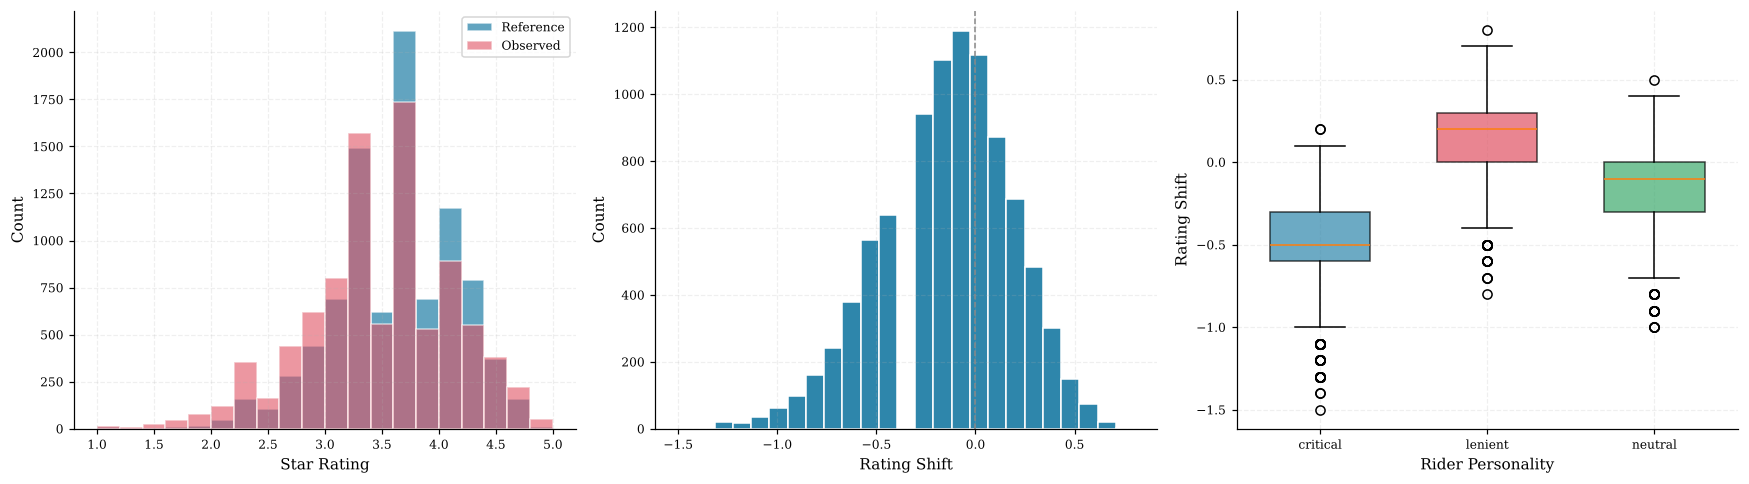

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(df_raw["original_star_rating"], bins=20, alpha=.75, label="Reference", color=C1, edgecolor="white")
axes[0].hist(df_raw["star_rating"], bins=20, alpha=.6, label="Observed", color=C2, edgecolor="white")
axes[0].set_xlabel("Star Rating"); axes[0].set_ylabel("Count"); axes[0].legend()
axes[1].hist(df_raw["rating_shift"], bins=25, color=C1, edgecolor="white")
axes[1].axvline(0, ls="--", color=C6, lw=1)
axes[1].set_xlabel("Rating Shift"); axes[1].set_ylabel("Count")
labels, data = zip(*sorted((k, v.values) for k, v in df_raw.groupby("rider_personality")["rating_shift"]))
bp = axes[2].boxplot(data, patch_artist=True, widths=0.6)
axes[2].set_xticks(range(1, len(labels) + 1)); axes[2].set_xticklabels(labels)
for patch, c in zip(bp["boxes"], [C1, C2, C3]):
    patch.set_facecolor(c); patch.set_alpha(0.7)
axes[2].set_xlabel("Rider Personality"); axes[2].set_ylabel("Rating Shift")
plt.tight_layout(); savefig("fig2"); plt.show()

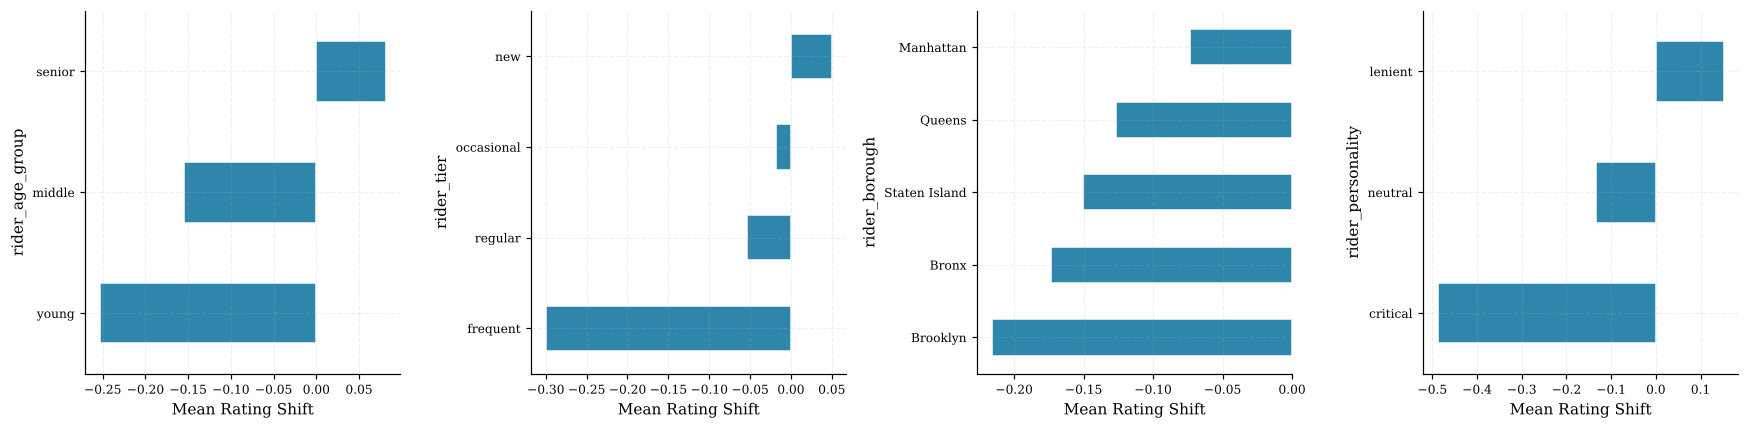

In [5]:
cat_cols = ["rider_age_group", "rider_tier", "rider_borough", "rider_personality"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cat_cols):
    df_raw.groupby(col)["rating_shift"].mean().sort_values().plot.barh(ax=ax, color=C1, edgecolor="white")
    ax.set_xlabel("Mean Rating Shift")
plt.tight_layout(); savefig("02_shift_by_groups"); plt.show()

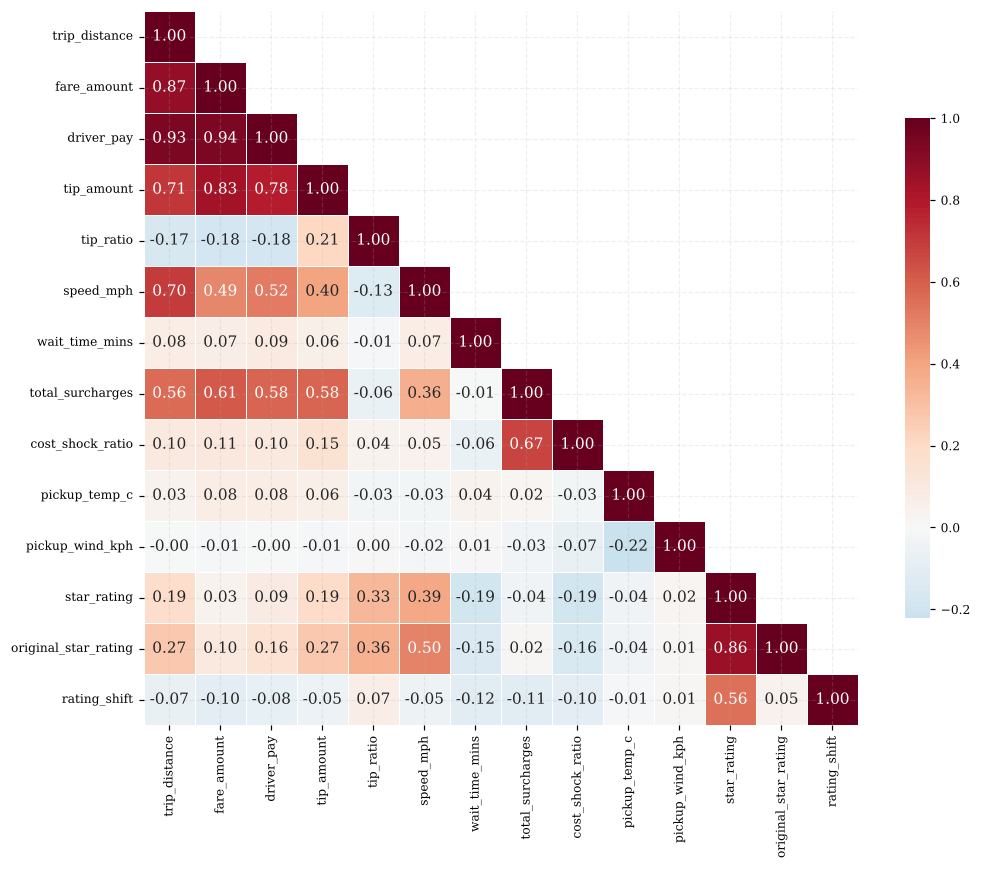

In [6]:
num_cols = ["trip_distance", "fare_amount", "driver_pay", "tip_amount", "tip_ratio",
            "speed_mph", "wait_time_mins", "total_surcharges", "cost_shock_ratio",
            "pickup_temp_c", "pickup_wind_kph", "star_rating", "original_star_rating", "rating_shift"]
corr = df_raw[num_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), square=True, linewidths=.5, cbar_kws={"shrink": .7})
plt.tight_layout(); savefig("03_correlation_heatmap"); plt.show()

## 3. Preprocessing

Wait time bins are short (below 3 minutes), medium (3 to 8), and long (8 or more). Distance bins are short (below 2 miles), medium (2 to 6), and long (6 or more). Cost shock bins are low (below 0.10), medium (0.10 to 0.30), and high (0.30 or more). Weather is snow, rain, windy (wind of at least 30 km/h), or clear. Trips are sorted by pickup time.

In [7]:
df = df_raw.copy()
df["observed"] = df["star_rating"]
df["clean_ref"] = df["original_star_rating"]
df["review_text_final"] = df["biased_review_text"].fillna(df["review_text"]).fillna("")

for col in ["request_time", "pickup_time", "dropoff_time"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

def _wbin(x):
    if pd.isna(x): return "unknown"
    return "short" if x < 3 else ("medium" if x < 8 else "long")
def _weath(row):
    if row["pickup_is_snow"] == True: return "snow"
    if row["pickup_is_rain"] == True: return "rain"
    if row["pickup_wind_kph"] >= 30: return "windy"
    return "clear"
def _csbin(x):
    if pd.isna(x): return "unknown"
    return "low" if x < 0.10 else ("medium" if x < 0.30 else "high")
def _dbin(x):
    if pd.isna(x): return "unknown"
    return "short" if x < 2 else ("medium" if x < 6 else "long")

df["wait_bin"] = df["wait_time_mins"].apply(_wbin)
df["weather_bin"] = df.apply(_weath, axis=1)
df["cost_shock_bin"] = df["cost_shock_ratio"].apply(_csbin)
df["distance_bin"] = df["trip_distance"].apply(_dbin)

df = df.sort_values("pickup_time", kind="mergesort").reset_index(drop=True)

print(f"Trips without a weather record: {df['pickup_temp_c'].isna().sum()}")
print(df.loc[df["pickup_temp_c"].isna(), "weather_bin"].value_counts().to_dict())
for b in ["wait_bin", "weather_bin", "cost_shock_bin", "distance_bin"]:
    print(b, df[b].value_counts().to_dict())

Trips without a weather record: 40
{'clear': 40}
wait_bin {'medium': 5081, 'short': 3200, 'long': 877}
weather_bin {'clear': 7652, 'rain': 1356, 'snow': 133, 'windy': 17}
cost_shock_bin {'low': 5692, 'medium': 2812, 'high': 654}
distance_bin {'medium': 3380, 'short': 3120, 'long': 2658}


## 4. Context model

The target is the observed rating. Rider attributes are excluded. Trips are split by pickup time into 70 percent training, 15 percent validation, and 15 percent test. The model with the lowest validation MAE is selected and all models are reported on the test set against the observed rating (Table 3, Panel I).

In [8]:
CTX_NUM = ["trip_distance", "fare_amount", "driver_pay", "driver_pay_ratio",
           "tip_amount", "tip_ratio", "speed_mph", "wait_time_mins",
           "total_surcharges", "cost_shock_ratio", "pickup_hour", "pickup_dow",
           "pickup_temp_c", "pickup_precip_mm", "pickup_snow_cm", "pickup_wind_kph",
           "duration_mins"]
CTX_CAT = ["is_weekend", "is_late_night", "pickup_is_snow", "pickup_is_rain",
           "wait_bin", "weather_bin", "cost_shock_bin", "distance_bin"]
for c in CTX_CAT:
    df[c] = df[c].astype(str)

X_all = df[CTX_NUM + CTX_CAT]
y_all = df["observed"]

preprocessor = ColumnTransformer([
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median"))]), CTX_NUM),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CTX_CAT),
])

def catboost_pipe():
    return SkPipeline([("pre", preprocessor),
                       ("model", CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05,
                                                   random_seed=42, verbose=0))])

In [9]:
n = len(df)
tr_end, va_end = int(n * 0.70), int(n * 0.85)
X_tr, y_tr = X_all.iloc[:tr_end], y_all.iloc[:tr_end]
X_va, y_va = X_all.iloc[tr_end:va_end], y_all.iloc[tr_end:va_end]
X_te, y_te = X_all.iloc[va_end:], y_all.iloc[va_end:]
pt = df["pickup_time"]
split_info = pd.DataFrame([
    {"Split": "Train", "Trips": len(X_tr), "From": pt.iloc[0], "To": pt.iloc[tr_end - 1]},
    {"Split": "Validation", "Trips": len(X_va), "From": pt.iloc[tr_end], "To": pt.iloc[va_end - 1]},
    {"Split": "Test", "Trips": len(X_te), "From": pt.iloc[va_end], "To": pt.iloc[-1]},
])
print(split_info.to_string(index=False))

     Split  Trips                From                  To
     Train   6410 2025-01-01 02:59:00 2025-06-27 22:33:00
Validation   1374 2025-06-27 22:38:00 2025-07-27 17:12:00
      Test   1374 2025-07-27 18:25:00 2025-09-30 23:21:00


In [10]:
MODELS = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=500, max_depth=6, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05, random_seed=42, verbose=0),
}
val_scores, fitted, test_rows = {}, {}, []
for name, model in MODELS.items():
    pipe = SkPipeline([("pre", preprocessor), ("model", model)]).fit(X_tr, y_tr)
    fitted[name] = pipe
    val_scores[name] = mean_absolute_error(y_va, pipe.predict(X_va))
    p = pipe.predict(X_te)
    test_rows.append({"Model": name, "Val MAE": val_scores[name], "Test MAE": mean_absolute_error(y_te, p),
                      "Test RMSE": _rmse(y_te, p), "Test R2": r2_score(y_te, p)})
best_name = min(val_scores, key=val_scores.get)
ctx_df = pd.DataFrame(test_rows).sort_values("Test MAE")
print(f"Selected by validation MAE: {best_name}")
print(ctx_df.round(4).to_string(index=False))

Selected by validation MAE: CatBoost
       Model  Val MAE  Test MAE  Test RMSE  Test R2
    CatBoost   0.2931    0.2923     0.3693   0.6695
     XGBoost   0.2978    0.2956     0.3785   0.6530
    LightGBM   0.2958    0.2961     0.3777   0.6543
RandomForest   0.3208    0.3246     0.4100   0.5928
       Ridge   0.3726    0.3692     0.4636   0.4794


### 4.1 Cross validation over consecutive time blocks

The five folds are consecutive blocks in time order. The column `Trained on later trips` shows which folds use later months for training. The predictions from these folds are the context predictions used in the correction.

In [11]:
n = len(df)
oof = np.full(n, np.nan)
fold_rows = []
for k, (tr_i, te_i) in enumerate(KFold(n_splits=5, shuffle=False).split(X_all), start=1):
    pipe = catboost_pipe().fit(X_all.iloc[tr_i], y_all.iloc[tr_i])
    oof[te_i] = pipe.predict(X_all.iloc[te_i])
    fold_rows.append({"Fold": k,
                      "Test from": df["pickup_time"].iloc[te_i[0]].date(),
                      "Test to": df["pickup_time"].iloc[te_i[-1]].date(),
                      "Trained on later trips": bool(tr_i.max() > te_i.max()),
                      "MAE": mean_absolute_error(y_all.iloc[te_i], oof[te_i]),
                      "RMSE": _rmse(y_all.iloc[te_i], oof[te_i]),
                      "R2": r2_score(y_all.iloc[te_i], oof[te_i])})
cv_df = pd.DataFrame(fold_rows)
print(cv_df.round(4).to_string(index=False))
print(f"MAE {cv_df['MAE'].mean():.4f} +/- {cv_df['MAE'].std():.4f}, "
      f"RMSE {cv_df['RMSE'].mean():.4f} +/- {cv_df['RMSE'].std():.4f}, "
      f"R2 {cv_df['R2'].mean():.4f} +/- {cv_df['R2'].std():.4f}")

df["ctx_expected"] = oof
df["ctx_residual"] = df["observed"] - df["ctx_expected"]
print(f"Context residual mean {df['ctx_residual'].mean():.4f}, std {df['ctx_residual'].std():.4f}")

 Fold  Test from    Test to  Trained on later trips    MAE   RMSE     R2
    1 2025-01-01 2025-02-09                    True 0.2760 0.3494 0.6901
    2 2025-02-09 2025-03-27                    True 0.2978 0.3776 0.6643
    3 2025-03-27 2025-06-11                    True 0.2885 0.3724 0.6739
    4 2025-06-11 2025-07-17                    True 0.2929 0.3716 0.6635
    5 2025-07-17 2025-09-30                   False 0.2927 0.3715 0.6578
MAE 0.2896 +/- 0.0083, RMSE 0.3685 +/- 0.0109, R2 0.6699 +/- 0.0127
Context residual mean -0.0011, std 0.3686


### 4.2 Forward looking check

Each fold is trained only on earlier trips (expanding window). This is reported for comparison and is not used downstream.

In [12]:
fwd_rows = []
for k, (tr_i, te_i) in enumerate(TimeSeriesSplit(n_splits=5).split(X_all), start=1):
    p = catboost_pipe().fit(X_all.iloc[tr_i], y_all.iloc[tr_i]).predict(X_all.iloc[te_i])
    fwd_rows.append({"Fold": k, "Train trips": len(tr_i), "Test trips": len(te_i),
                     "MAE": mean_absolute_error(y_all.iloc[te_i], p), "RMSE": _rmse(y_all.iloc[te_i], p),
                     "R2": r2_score(y_all.iloc[te_i], p)})
fwd_df = pd.DataFrame(fwd_rows)
print(fwd_df.round(4).to_string(index=False))
print(f"MAE {fwd_df['MAE'].mean():.4f} +/- {fwd_df['MAE'].std():.4f}")

 Fold  Train trips  Test trips    MAE   RMSE     R2
    1         1528        1526 0.3060 0.3926 0.6283
    2         3054        1526 0.3114 0.4013 0.6234
    3         4580        1526 0.2917 0.3730 0.6768
    4         6106        1526 0.2969 0.3775 0.6274
    5         7632        1526 0.2918 0.3678 0.6716
MAE 0.2995 +/- 0.0088


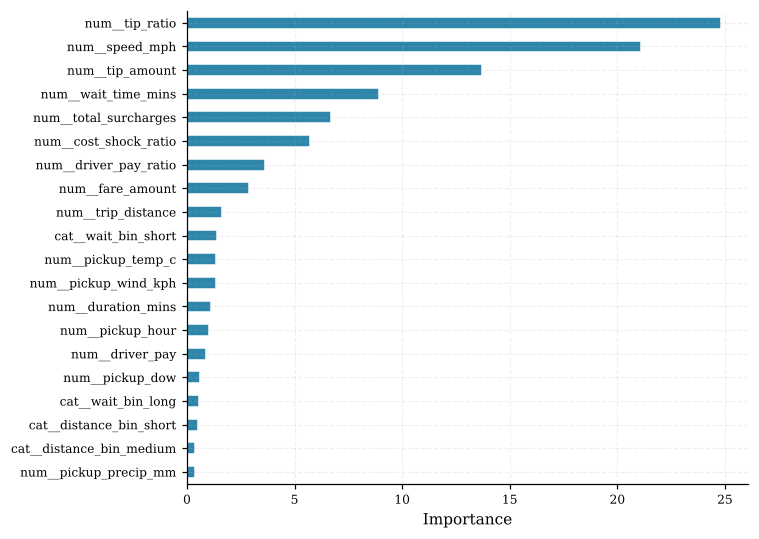

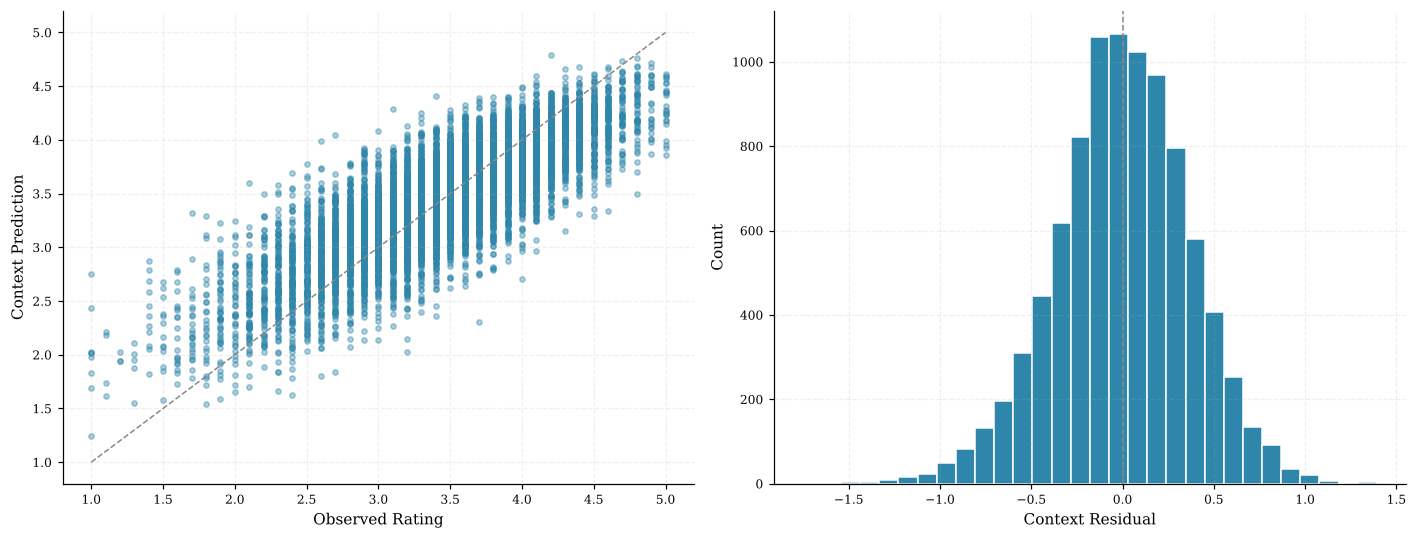

In [13]:
fi_model = catboost_pipe().fit(X_tr, y_tr)
fi = pd.Series(fi_model.named_steps["model"].feature_importances_,
               index=fi_model.named_steps["pre"].get_feature_names_out()).sort_values().tail(20)
fig, ax = plt.subplots(figsize=(7, 5))
fi.plot.barh(ax=ax, color=C1, edgecolor="white"); ax.set_xlabel("Importance")
plt.tight_layout(); savefig("04_feature_importance"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df["observed"], df["ctx_expected"], alpha=.4, s=12, color=C1)
axes[0].plot([1, 5], [1, 5], "--", color=C6, lw=1)
axes[0].set_xlabel("Observed Rating"); axes[0].set_ylabel("Context Prediction")
axes[1].hist(df["ctx_residual"], bins=30, color=C1, edgecolor="white")
axes[1].axvline(0, ls="--", color=C6, lw=1)
axes[1].set_xlabel("Context Residual"); axes[1].set_ylabel("Count")
plt.tight_layout(); savefig("05_context_diagnostics"); plt.show()

            Group  Observed rating gap  Context residual gap
         wait_bin               0.3907                0.0068
      weather_bin               0.1515                0.1706
   cost_shock_bin               0.2888                0.0060
     distance_bin               0.3857                0.0029
  rider_age_group               0.3256                0.2190
    rider_borough               0.1357                0.0938
       rider_tier               0.3654                0.2372
rider_personality               0.6704                0.4347


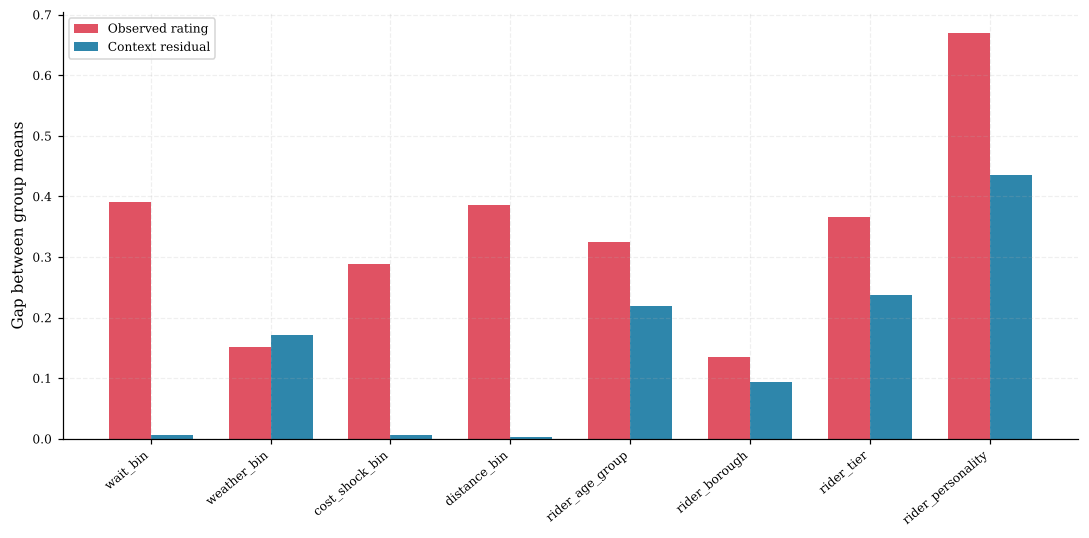

In [14]:
def parity_gap(data, col, group):
    gm = data.groupby(group)[col].mean()
    return gm.max() - gm.min()

GROUPS = ["wait_bin", "weather_bin", "cost_shock_bin", "distance_bin",
          "rider_age_group", "rider_borough", "rider_tier", "rider_personality"]
res_gap = pd.DataFrame([{"Group": g, "Observed rating gap": parity_gap(df, "observed", g),
                         "Context residual gap": parity_gap(df, "ctx_residual", g)} for g in GROUPS])
print(res_gap.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(res_gap)); w = 0.35
ax.bar(x - w/2, res_gap["Observed rating gap"], w, label="Observed rating", color=C2)
ax.bar(x + w/2, res_gap["Context residual gap"], w, label="Context residual", color=C1)
ax.set_xticks(x); ax.set_xticklabels(res_gap["Group"], rotation=40, ha="right")
ax.set_ylabel("Gap between group means"); ax.legend()
plt.tight_layout(); savefig("06_residual_parity"); plt.show()

## 5. Rater score from earlier trips only

$$u_r = \sigma(1.5 - 3.0E_r - 3.0I_r - 2.0C_r - 2.5H_r + 1.5M_r)$$

All terms use only the rider's earlier trips in pickup order. $E_r$ is the share of earlier ratings that round to 1 or 5. $I_r$ is the share of earlier reviews whose sentiment and rating disagree. $C_r$ is the largest share of earlier trips with one driver. $H_r$ is the negative mean context residual over earlier trips, limited to 0 to 0.5. $M_r$ is 0.1, 0.3, 0.6, or 1.0 for at most 1, 2 to 3, 4 to 7, or 8 or more earlier trips. A first trip has $E_r = I_r = C_r = H_r = 0$ and $M_r = 0.1$. No persona, demographic, or tier label is used. The weights are set by hand.

In [15]:
analyzer = SentimentIntensityAnalyzer()
df["sentiment"] = df["review_text_final"].apply(lambda x: analyzer.polarity_scores(str(x))["compound"])
df["is_extreme"] = df["star_rating_int"].isin([1, 5]).astype(int)
df["is_inconsistent"] = (((df["sentiment"] > 0.3) & (df["observed"] <= 2.5)) |
                         ((df["sentiment"] < -0.3) & (df["observed"] >= 4.0))).astype(int)

g = df.groupby("rider_id", sort=False)
prev_n = g.cumcount()

def past_mean(col):
    return ((g[col].cumsum() - df[col]) / prev_n.replace(0, np.nan)).fillna(0.0)

df["E_r"] = past_mean("is_extreme")
df["I_r"] = past_mean("is_inconsistent")
df["H_r"] = (-past_mean("ctx_residual")).clip(0, 0.5)

conc, seen = [], {}
for r, d in zip(df["rider_id"], df["driver_id"]):
    h = seen.setdefault(r, {})
    tot = sum(h.values())
    conc.append(max(h.values()) / tot if tot else 0.0)
    h[d] = h.get(d, 0) + 1
df["C_r"] = conc

def _mat(k):
    if k <= 1: return 0.1
    if k <= 3: return 0.3
    if k <= 7: return 0.6
    return 1.0
df["prev_trips"] = prev_n
df["M_r"] = prev_n.apply(_mat)

df["reliability"] = expit(1.5 - 3.0 * df["E_r"] - 3.0 * df["I_r"] - 2.0 * df["C_r"]
                          - 2.5 * df["H_r"] + 1.5 * df["M_r"])

print(f"Riders with at least one trip: {df['rider_id'].nunique()}")
print(f"Trips with no earlier history for the rider: {(prev_n == 0).sum()}")
print(df["reliability"].describe().round(4).to_dict())

Riders with at least one trip: 783
Trips with no earlier history for the rider: 783
{'count': 9158.0, 'mean': 0.7796, 'std': 0.192, 'min': 0.01, '25%': 0.7211, '50%': 0.8414, '75%': 0.9101, 'max': 0.9483}


In [16]:
by_persona = df.groupby("rider_personality")["reliability"].agg(["mean", "std", "count"])
print(by_persona.round(4).to_string())
crit = df.loc[df["rider_personality"] == "critical", "reliability"].mean()
noncrit = df.loc[df["rider_personality"] != "critical", "reliability"].mean()
print(f"Critical {crit:.4f}, non critical {noncrit:.4f}, difference {noncrit - crit:.4f}")

                     mean     std  count
rider_personality                       
critical           0.7059  0.2039   2205
lenient            0.8089  0.1825   2477
neutral            0.7998  0.1816   4476
Critical 0.7059, non critical 0.8030, difference 0.0971


## 6. Review category

In [17]:
DRIVER_KW = ["rude", "unsafe", "wrong route", "bad driving", "unprofessional",
             "late pickup", "reckless", "speeding", "ignored", "unfriendly",
             "aggressive", "could have been more professional",
             "less comfortable than expected", "did not feel safe"]
PLATFORM_KW = ["surge", "overpriced", "expensive", "surcharge", "extra fee",
               "unexpected fee", "charged too much", "app crash",
               "cancellation fee", "billing", "overcharged",
               "not worth the price", "not worth it", "for the price",
               "too much money", "pricing"]
ENVIRON_KW = ["traffic", "rain", "snow", "road", "construction",
              "accident", "congestion", "storm", "delay", "flooding",
              "weather", "cold", "icy", "slippery"]

def _kw_classify(text, sentiment):
    t = str(text).lower()
    d = sum(k in t for k in DRIVER_KW)
    p = sum(k in t for k in PLATFORM_KW)
    e = sum(k in t for k in ENVIRON_KW)
    if sentiment < 0.0:
        p += sum(k in t for k in ["fare", "fee", "price", "payment", "charged"]) * 0.5
        d += ("driver" in t) * 0.3
    scores = {"DRIVER": d, "PLATFORM": p, "ENVIRONMENT": e}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "UNKNOWN"

df["kw_label"] = [_kw_classify(t, s) for t, s in zip(df["review_text_final"], df["sentiment"])]
tfidf = TfidfVectorizer(max_features=500, stop_words="english", ngram_range=(1, 2))
X_text = tfidf.fit_transform(df["review_text_final"])
clf = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced").fit(X_text, df["kw_label"])
df["review_cat"] = clf.predict(X_text)
print(df["review_cat"].value_counts().to_dict())
print(f"Agreement between classifier and keyword labels: {(df['review_cat'] == df['kw_label']).mean():.3f}")

{'ENVIRONMENT': 5381, 'PLATFORM': 2321, 'UNKNOWN': 1146, 'DRIVER': 310}
Agreement between classifier and keyword labels: 0.880


## 7. Telemetry score

$Q_j = 1 - (0.25w_j + 0.25c_j + 0.20s_j + 0.15v_j)$ with each input scaled to 0 to 1 over all trips. Wait time is pickup minus request in minutes. Cost shock is total surcharges divided by fare.

In [18]:
def _mm(s):
    s = s.astype(float)
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

W_WAIT, W_CSHOCK, W_SURCH, W_LOSPD = 0.25, 0.25, 0.20, 0.15
df["wait_n"] = _mm(df["wait_time_mins"])
df["cshock_n"] = _mm(df["cost_shock_ratio"])
df["surch_n"] = _mm(df["total_surcharges"])
df["lospd_n"] = 1 - _mm(df["speed_mph"])
df["telemetry_q"] = (1 - (W_WAIT * df["wait_n"] + W_CSHOCK * df["cshock_n"]
                          + W_SURCH * df["surch_n"] + W_LOSPD * df["lospd_n"])).clip(0, 1)

surch_check = (df["tolls"] + df["congestion_surcharge"] + df["airport_fee"] + df["cbd_congestion_fee"] - df["total_surcharges"]).abs().max()
cs_check = (df["total_surcharges"] / df["fare_amount"] - df["cost_shock_ratio"]).abs().max()
print(f"Max gap between total_surcharges and the sum of its parts: {surch_check:.4f}")
print(f"Max gap between cost_shock_ratio and surcharges divided by fare: {cs_check:.6f}")
print(df["telemetry_q"].describe().round(4).to_dict())
print(f"Share of trips with a positive telemetry term: {(df['telemetry_q'] > 0.5).mean():.3f}")

Max gap between total_surcharges and the sum of its parts: 0.0000
Max gap between cost_shock_ratio and surcharges divided by fare: 0.000000
{'count': 9158.0, 'mean': 0.8316, 'std': 0.0462, 'min': 0.556, '25%': 0.8022, '50%': 0.8441, '75%': 0.8624, 'max': 0.9752}
Share of trips with a positive telemetry term: 1.000


## 8. Bounded additive correction

Weights are selected by grid search against the reference rating over all trips. Section 15 repeats the selection on the first 70 percent of trips only and evaluates on the last 15 percent.

In [19]:
CAT_AMP = {"DRIVER": 0.05, "PLATFORM": 0.90, "ENVIRONMENT": 0.85, "UNKNOWN": 0.35}
TAU = 1.0
MAX_CORR = 2.0
ALPHA_GRID = np.round(np.arange(0.2, 1.6, 0.1), 2)
BETA_GRID = np.round(np.arange(0.1, 1.2, 0.1), 2)
GAMMA_GRID = np.round(np.arange(0.1, 1.2, 0.1), 2)

phi_rev = df["review_cat"].map(CAT_AMP)
phi_rel = 1 - df["reliability"]
phi_tel = (df["telemetry_q"] - 0.5).clip(0, 0.5)

def compute_fairrate(alpha, beta, gamma, tau=TAU, max_corr=MAX_CORR, data=None):
    d = df if data is None else data
    bounded_res = np.tanh(d["ctx_residual"] / tau) * tau
    signal = (alpha * d["review_cat"].map(CAT_AMP)
              + beta * (1 - d["reliability"])
              + gamma * (d["telemetry_q"] - 0.5).clip(0, 0.5))
    correction = (signal * (-bounded_res)).clip(-max_corr, max_corr)
    return (d["observed"] + correction).clip(1.0, 5.0), correction

def grid_search(mask=None):
    m = np.ones(len(df), bool) if mask is None else np.asarray(mask)
    best_mae, best = np.inf, None
    for a in ALPHA_GRID:
        for b in BETA_GRID:
            for c in GAMMA_GRID:
                fr, _ = compute_fairrate(a, b, c)
                mae = mean_absolute_error(df["clean_ref"][m], fr[m])
                if mae < best_mae:
                    best_mae, best = mae, (a, b, c)
    return best, best_mae

In [20]:
(ALPHA_OPT, BETA_OPT, GAMMA_OPT), best_mae = grid_search()
print(f"Grid size: {len(ALPHA_GRID) * len(BETA_GRID) * len(GAMMA_GRID)}")
print(f"Selected: alpha={ALPHA_OPT}, beta={BETA_OPT}, gamma={GAMMA_OPT}")
for nm, v, grid in [("alpha", ALPHA_OPT, ALPHA_GRID), ("beta", BETA_OPT, BETA_GRID), ("gamma", GAMMA_OPT, GAMMA_GRID)]:
    print(f"{nm} on grid edge: {v in (grid.min(), grid.max())}")

df["fairrate"], df["correction"] = compute_fairrate(ALPHA_OPT, BETA_OPT, GAMMA_OPT)
unclipped = df["observed"] + df["correction"]
print(f"MAE observed {mean_absolute_error(df['clean_ref'], df['observed']):.4f}, FairRate {best_mae:.4f}")
print(f"Largest absolute correction: {df['correction'].abs().max():.4f}")
print(f"Trips at the correction cap: {(df['correction'].abs() >= MAX_CORR).sum()}")
print(f"Trips outside 1 to 5 before the final clip: {((unclipped < 1) | (unclipped > 5)).sum()}")

Grid size: 1694
Selected: alpha=0.2, beta=0.6, gamma=0.8
alpha on grid edge: True
beta on grid edge: False
gamma on grid edge: False
MAE observed 0.2779, FairRate 0.2437
Largest absolute correction: 0.7472
Trips at the correction cap: 0
Trips outside 1 to 5 before the final clip: 0


## 9. Reputation update (EMA with per trip cap)

{'count': 179.0, 'mean': 0.6194, 'std': 0.0409, 'min': 0.5166, '25%': 0.5935, '50%': 0.6225, '75%': 0.6465, 'max': 0.7303}


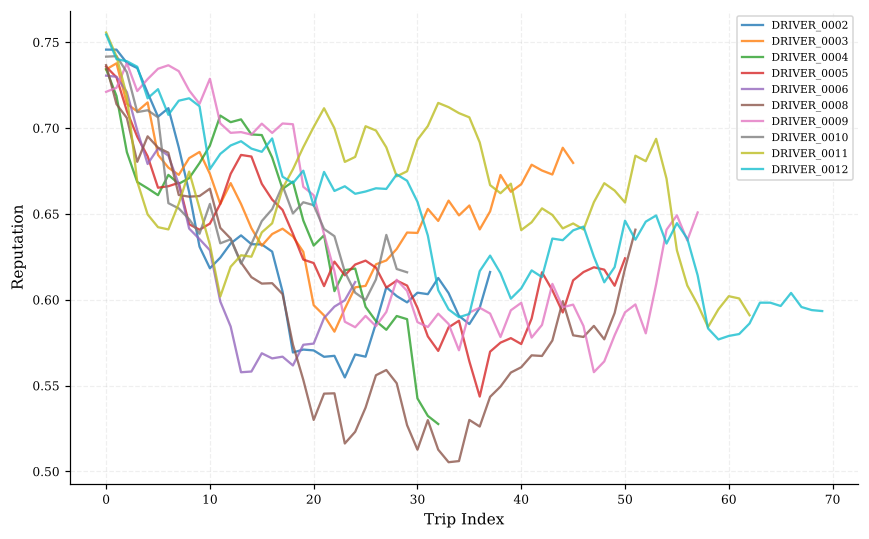

In [21]:
LAMBDA, DELTA, INIT = 0.90, 0.05, 0.75

def run_ema(data, col, lam=LAMBDA, delta=DELTA, init=INIT):
    dfs = data.sort_values(["driver_id", "pickup_time"], kind="mergesort")
    reps, hist = {}, []
    for d, v in zip(dfs["driver_id"], dfs[col]):
        old = reps.get(d, init)
        new = float(np.clip(lam * old + (1 - lam) * (v - 1) / 4, old - delta, old + delta))
        reps[d] = new
        hist.append({"driver_id": d, "old": old, "new": new})
    return pd.DataFrame(hist)

rep_fair = run_ema(df, "fairrate")
rep_raw = run_ema(df, "observed")
print(rep_fair.groupby("driver_id").tail(1)["new"].describe().round(4).to_dict())

fig, ax = plt.subplots(figsize=(8, 5))
for d in sorted(df["driver_id"].unique())[:10]:
    ax.plot(rep_fair.loc[rep_fair["driver_id"] == d, "new"].values, label=d, alpha=.8)
ax.set_xlabel("Trip Index"); ax.set_ylabel("Reputation"); ax.legend(fontsize=7)
plt.tight_layout(); savefig("07_reputation"); plt.show()

## 10. FairRate and component variants (Table 3, Panel II)

All rows use all 9,158 trips against the reference rating. The context calibrated row uses the context prediction as the rating. Single component rows keep one tuned weight and set the others to zero.

            Method    MAE   RMSE     R2
     Full FairRate 0.2437 0.3082 0.6674
    Telemetry Only 0.2540 0.3244 0.6314
  Reliability Only 0.2633 0.3367 0.6029
       Review Only 0.2635 0.3395 0.5962
   Observed Biased 0.2779 0.3602 0.5455
Context-Calibrated 0.2816 0.3534 0.5626


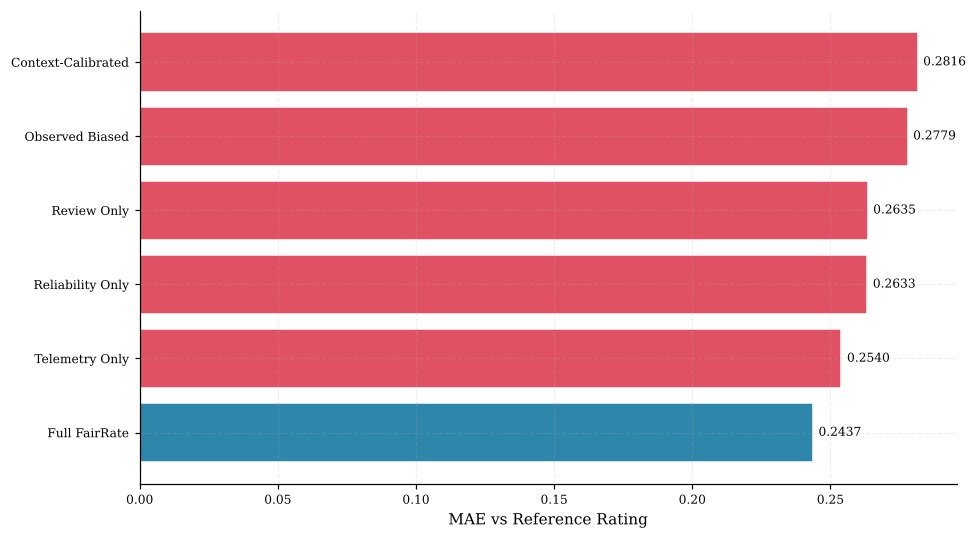

In [22]:
df["bl_ctx"] = df["ctx_expected"]
df["bl_rel"], _ = compute_fairrate(0, BETA_OPT, 0)
df["bl_rev"], _ = compute_fairrate(ALPHA_OPT, 0, 0)
df["bl_tel"], _ = compute_fairrate(0, 0, GAMMA_OPT)
methods = {"Full FairRate": "fairrate", "Reliability Only": "bl_rel", "Telemetry Only": "bl_tel",
           "Review Only": "bl_rev", "Observed Biased": "observed", "Context-Calibrated": "bl_ctx"}
bl_df = pd.DataFrame([metric_row(m, df["clean_ref"], df[c]) for m, c in methods.items()]).sort_values("MAE")
print(bl_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
b = bl_df.sort_values("MAE")
ax.barh(b["Method"], b["MAE"], color=[C1 if m == "Full FairRate" else C2 for m in b["Method"]], edgecolor="white")
for i, v in enumerate(b["MAE"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("MAE vs Reference Rating")
plt.tight_layout(); savefig("08_baseline_mae"); plt.show()

## 11. Trip level change and significance

MAE reduction 0.0343 stars (12.3%)
Trips improved 56.6%, worse 43.4%, unchanged 0.0%
Mean increase on worse trips 0.1107, mean decrease on improved trips 0.1453
Wilcoxon p=5.03e-72, paired t p=1.40e-88


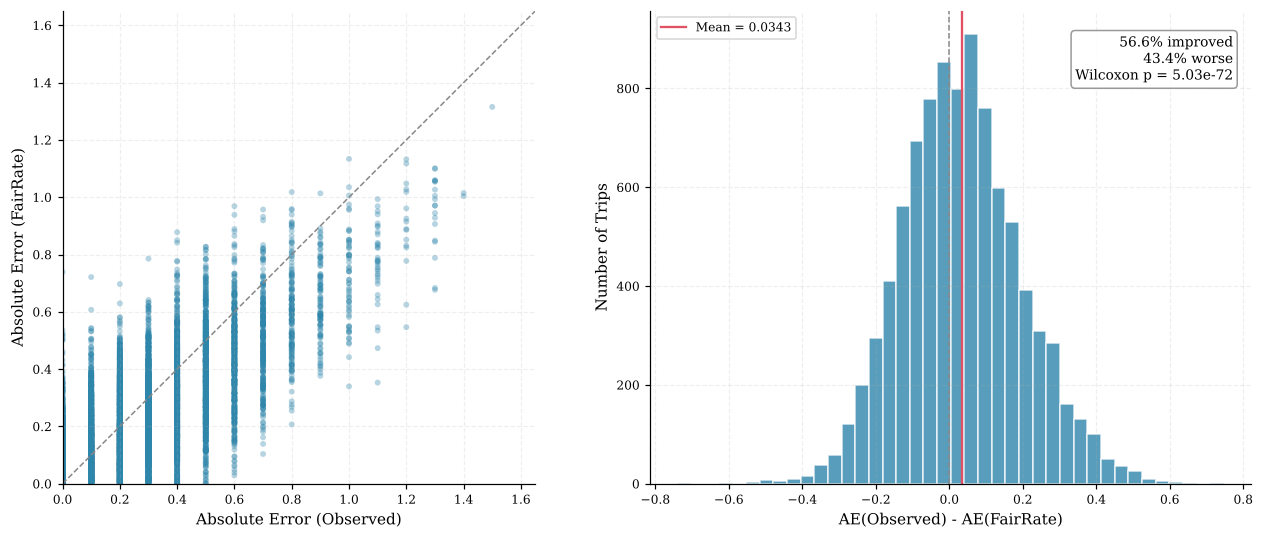

In [23]:
ae_raw = (df["clean_ref"] - df["observed"]).abs()
ae_fair = (df["clean_ref"] - df["fairrate"]).abs()
ae_diff = ae_raw - ae_fair
sw, pw = wilcoxon(ae_raw, ae_fair, alternative="greater")
st, ptt = ttest_rel(ae_raw, ae_fair)
print(f"MAE reduction {ae_diff.mean():.4f} stars ({(1 - ae_fair.mean() / ae_raw.mean()) * 100:.1f}%)")
print(f"Trips improved {(ae_diff > 0).mean() * 100:.1f}%, worse {(ae_diff < 0).mean() * 100:.1f}%, unchanged {(ae_diff == 0).mean() * 100:.1f}%")
print(f"Mean increase on worse trips {(-ae_diff[ae_diff < 0]).mean():.4f}, mean decrease on improved trips {ae_diff[ae_diff > 0].mean():.4f}")
print(f"Wilcoxon p={pw:.2e}, paired t p={ptt:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
hi = max(ae_raw.max(), ae_fair.max()) * 1.1
ax.scatter(ae_raw, ae_fair, color=C1, alpha=0.35, s=15, edgecolors="none")
ax.plot([0, hi], [0, hi], "--", color=C6, lw=1)
ax.set_xlabel("Absolute Error (Observed)"); ax.set_ylabel("Absolute Error (FairRate)")
ax.set_xlim(0, hi); ax.set_ylim(0, hi); ax.set_aspect("equal")
ax = axes[1]
ax.hist(ae_diff, bins=40, color=C1, edgecolor="white", alpha=0.8)
ax.axvline(0, ls="--", color=C6, lw=1)
ax.axvline(ae_diff.mean(), color=C2, lw=1.5, label=f"Mean = {ae_diff.mean():.4f}")
ax.set_xlabel("AE(Observed) - AE(FairRate)"); ax.set_ylabel("Number of Trips")
ax.text(0.97, 0.95, f"{(ae_diff > 0).mean()*100:.1f}% improved\n{(ae_diff < 0).mean()*100:.1f}% worse\nWilcoxon p = {pw:.2e}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=C6, alpha=0.85))
ax.legend(fontsize=8)
plt.tight_layout(); savefig("16_statistical_significance"); plt.show()

## 12. Rating gaps before and after correction

The gap for a partition is the largest group mean rating minus the smallest group mean rating.

            Group  Observed Gap  FairRate Gap  Reference Gap
         wait_bin        0.3907        0.3933         0.2718
      weather_bin        0.1515        0.0777         0.0752
   cost_shock_bin        0.2888        0.2865         0.2138
     distance_bin        0.3857        0.3869         0.4475
  rider_age_group        0.3256        0.2152         0.0094
    rider_borough        0.1357        0.0924         0.0292
       rider_tier        0.3654        0.2362         0.0296
rider_personality        0.6704        0.4520         0.0363


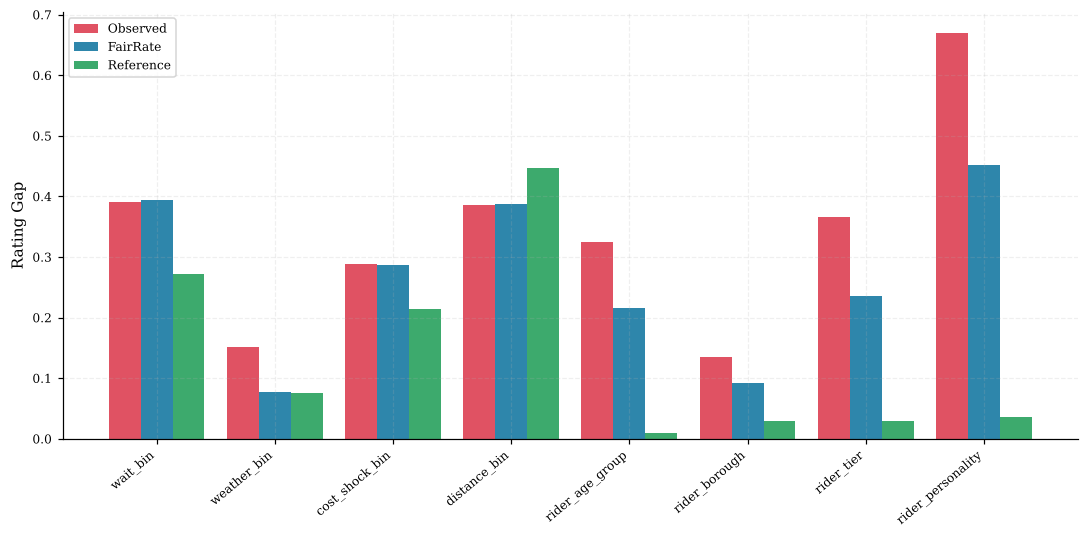

In [24]:
gap_df = pd.DataFrame([{"Group": g, "Observed Gap": parity_gap(df, "observed", g),
                        "FairRate Gap": parity_gap(df, "fairrate", g),
                        "Reference Gap": parity_gap(df, "clean_ref", g)} for g in GROUPS])
print(gap_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(gap_df)); w = 0.27
ax.bar(x - w, gap_df["Observed Gap"], w, label="Observed", color=C2)
ax.bar(x, gap_df["FairRate Gap"], w, label="FairRate", color=C1)
ax.bar(x + w, gap_df["Reference Gap"], w, label="Reference", color=C3)
ax.set_xticks(x); ax.set_xticklabels(gap_df["Group"], rotation=40, ha="right")
ax.set_ylabel("Rating Gap"); ax.legend()
plt.tight_layout(); savefig("09_parity_gap"); plt.show()

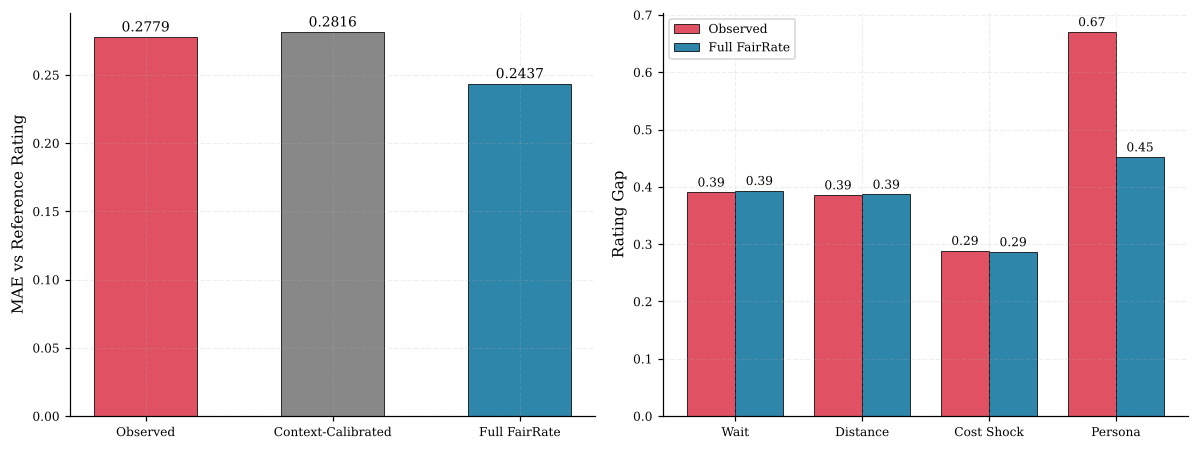

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
names = ["Observed", "Context-Calibrated", "Full FairRate"]
vals = [mean_absolute_error(df["clean_ref"], df[c]) for c in ["observed", "ctx_expected", "fairrate"]]
bars = ax.bar(names, vals, color=[C2, C6, C1], edgecolor="black", linewidth=0.5, width=0.55)
for bb, v in zip(bars, vals):
    ax.text(bb.get_x() + bb.get_width() / 2, v + 0.004, f"{v:.4f}", ha="center", fontsize=9)
ax.set_ylabel("MAE vs Reference Rating")
ax = axes[1]
sel = gap_df.set_index("Group").loc[["wait_bin", "distance_bin", "cost_shock_bin", "rider_personality"]]
lbl = ["Wait", "Distance", "Cost Shock", "Persona"]
x = np.arange(4); w = 0.38
b1 = ax.bar(x - w/2, sel["Observed Gap"], w, color=C2, label="Observed", edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + w/2, sel["FairRate Gap"], w, color=C1, label="Full FairRate", edgecolor="black", linewidth=0.5)
for bb in list(b1) + list(b2):
    ax.text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 0.01, f"{bb.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(lbl); ax.set_ylabel("Rating Gap"); ax.legend()
plt.tight_layout(); savefig("fig4"); plt.show()

## 13. Error by predicted review category (Table 4)

 review_cat    n  raw_mean  clean_mean  fair_mean  raw_mae  fair_mae  MAE Reduction
     DRIVER  310    2.9797      3.6990     3.1189   0.7265    0.5898         0.1367
ENVIRONMENT 5381    3.5262      3.6386     3.5210   0.2608    0.2302         0.0306
   PLATFORM 2321    3.3232      3.4838     3.3184   0.2752    0.2397         0.0355
    UNKNOWN 1146    3.5609      3.6459     3.5524   0.2424    0.2213         0.0212


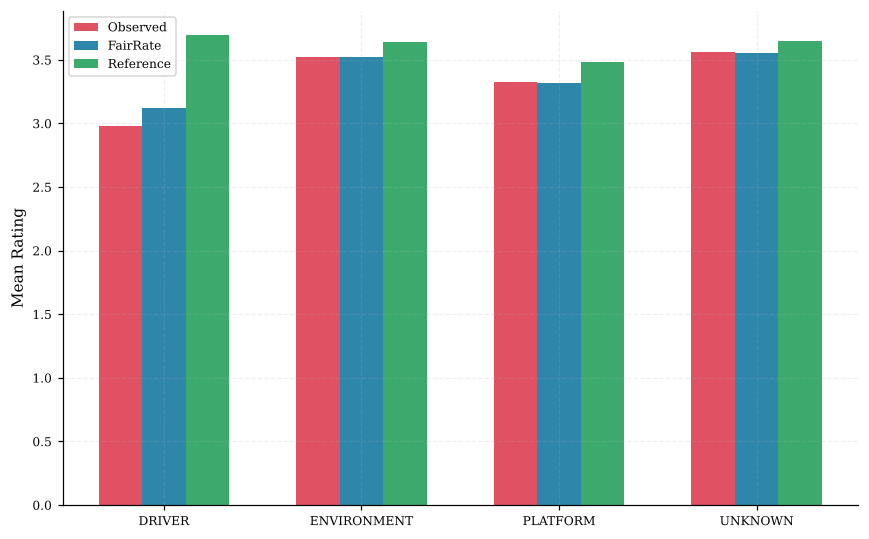

In [26]:
df["_ae_r"], df["_ae_f"] = ae_raw, ae_fair
cat_sum = df.groupby("review_cat").agg(n=("driver_id", "count"), raw_mean=("observed", "mean"),
                                       clean_mean=("clean_ref", "mean"), fair_mean=("fairrate", "mean"),
                                       raw_mae=("_ae_r", "mean"), fair_mae=("_ae_f", "mean")).reset_index()
cat_sum["MAE Reduction"] = cat_sum["raw_mae"] - cat_sum["fair_mae"]
df.drop(columns=["_ae_r", "_ae_f"], inplace=True)
print(cat_sum.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(cat_sum)); w = 0.22
ax.bar(x - w, cat_sum["raw_mean"], w, label="Observed", color=C2)
ax.bar(x, cat_sum["fair_mean"], w, label="FairRate", color=C1)
ax.bar(x + w, cat_sum["clean_mean"], w, label="Reference", color=C3)
ax.set_xticks(x); ax.set_xticklabels(cat_sum["review_cat"]); ax.set_ylabel("Mean Rating"); ax.legend()
plt.tight_layout(); savefig("10_category_protection"); plt.show()

## 14. Ablation (Table 3, Panel III)

Each removed weight is set to zero. The other weights keep their tuned values and are not retuned.

      Variant    MAE   RMSE     R2
Full FairRate 0.2437 0.3082 0.6674
      -Review 0.2452 0.3108 0.6617
 -Reliability 0.2470 0.3149 0.6527
   -Telemetry 0.2517 0.3215 0.6380
 Context Only 0.2816 0.3534 0.5626
No Correction 0.2779 0.3602 0.5455


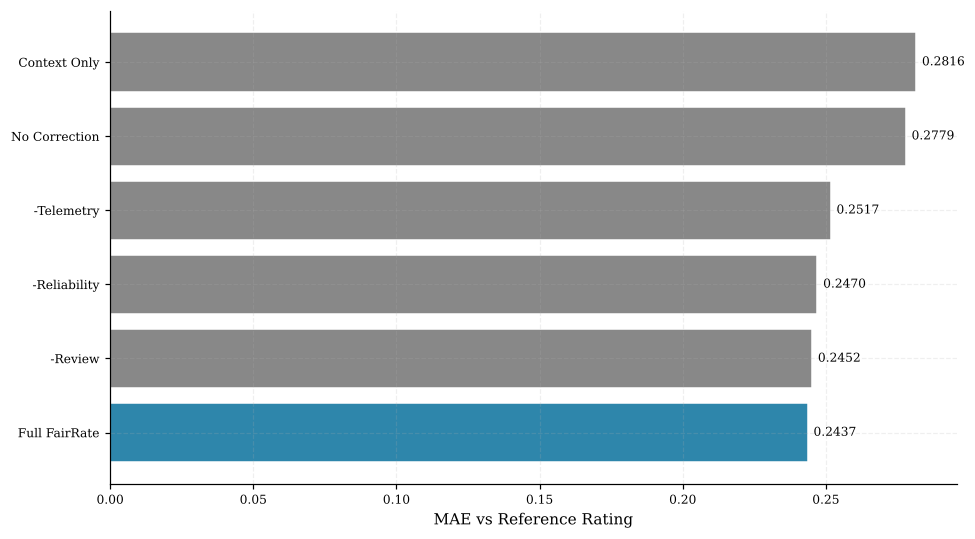

In [27]:
abl_cfgs = {"Full FairRate": (ALPHA_OPT, BETA_OPT, GAMMA_OPT),
            "-Review": (0, BETA_OPT, GAMMA_OPT),
            "-Reliability": (ALPHA_OPT, 0, GAMMA_OPT),
            "-Telemetry": (ALPHA_OPT, BETA_OPT, 0)}
abl_rows = [metric_row(k, df["clean_ref"], compute_fairrate(*v)[0]) for k, v in abl_cfgs.items()]
abl_rows.append(metric_row("Context Only", df["clean_ref"], df["ctx_expected"]))
abl_rows.append(metric_row("No Correction", df["clean_ref"], df["observed"]))
abl_df = pd.DataFrame(abl_rows).rename(columns={"Method": "Variant"})
print(abl_df.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
a = abl_df.sort_values("MAE")
ax.barh(a["Variant"], a["MAE"], color=[C1 if v == "Full FairRate" else C6 for v in a["Variant"]], edgecolor="white")
for i, v in enumerate(a["MAE"]):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlabel("MAE vs Reference Rating")
plt.tight_layout(); savefig("11_ablation"); plt.show()

## 15. Held out time test

Weights are selected using only the first 70 percent of trips in time order and applied unchanged to the last 15 percent. All context predictions for the last 15 percent come from the final fold, which is trained only on earlier trips.

In [28]:
idx = np.arange(len(df))
tune_mask = idx < tr_end
test_mask = idx >= va_end
(a_h, b_h, g_h), _ = grid_search(tune_mask)
fr_h, _ = compute_fairrate(a_h, b_h, g_h)
y_h = df["clean_ref"][test_mask]
mae_obs_h = mean_absolute_error(y_h, df["observed"][test_mask])
mae_fr_h = mean_absolute_error(y_h, fr_h[test_mask])
d_h = (y_h - df["observed"][test_mask]).abs() - (y_h - fr_h[test_mask]).abs()
print(f"Weights from first 70%: alpha={a_h}, beta={b_h}, gamma={g_h}")
print(f"Last 15% ({test_mask.sum()} trips): MAE observed {mae_obs_h:.4f}, FairRate {mae_fr_h:.4f}, "
      f"reduction {(1 - mae_fr_h / mae_obs_h) * 100:.1f}%")
print(f"Trips improved {(d_h > 0).mean() * 100:.1f}%, Wilcoxon p={wilcoxon(d_h, alternative='greater').pvalue:.2e}")
holdout_df = pd.DataFrame([{"alpha": a_h, "beta": b_h, "gamma": g_h, "test_trips": int(test_mask.sum()),
                            "MAE_observed": mae_obs_h, "MAE_fairrate": mae_fr_h}])

Weights from first 70%: alpha=0.2, beta=0.4, gamma=0.9
Last 15% (1374 trips): MAE observed 0.2724, FairRate 0.2436, reduction 10.6%
Trips improved 55.2%, Wilcoxon p=5.32e-10


## 16. Sensitivity

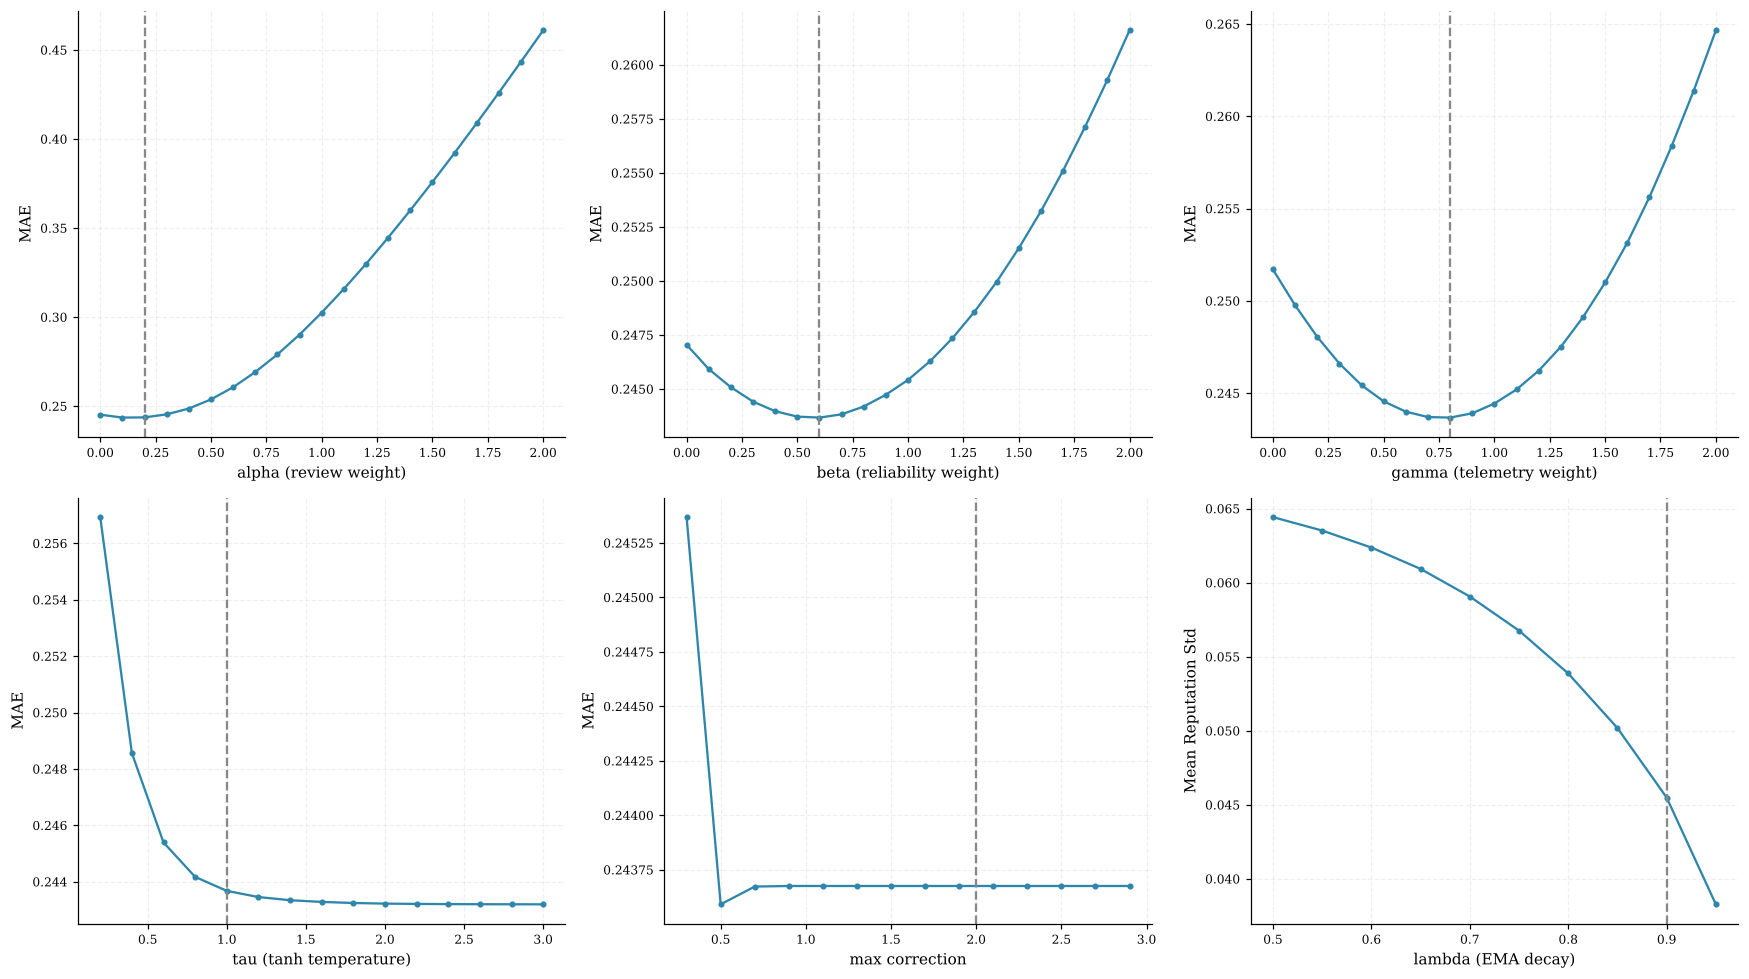

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
sweeps = [("alpha (review weight)", np.arange(0.0, 2.1, 0.1), lambda v: compute_fairrate(v, BETA_OPT, GAMMA_OPT)[0], ALPHA_OPT),
          ("beta (reliability weight)", np.arange(0.0, 2.1, 0.1), lambda v: compute_fairrate(ALPHA_OPT, v, GAMMA_OPT)[0], BETA_OPT),
          ("gamma (telemetry weight)", np.arange(0.0, 2.1, 0.1), lambda v: compute_fairrate(ALPHA_OPT, BETA_OPT, v)[0], GAMMA_OPT),
          ("tau (tanh temperature)", np.arange(0.2, 3.1, 0.2), lambda v: compute_fairrate(ALPHA_OPT, BETA_OPT, GAMMA_OPT, tau=v)[0], TAU),
          ("max correction", np.arange(0.3, 3.1, 0.2), lambda v: compute_fairrate(ALPHA_OPT, BETA_OPT, GAMMA_OPT, max_corr=v)[0], MAX_CORR)]
sens_rows = []
for ax, (lab, vals, fn, opt) in zip(axes, sweeps):
    maes = [mean_absolute_error(df["clean_ref"], fn(v)) for v in vals]
    sens_rows += [{"Parameter": lab, "Value": round(v, 2), "MAE": m} for v, m in zip(vals, maes)]
    ax.plot(vals, maes, "o-", color=C1, ms=3, lw=1.5); ax.axvline(opt, ls="--", color=C6)
    ax.set_xlabel(lab); ax.set_ylabel("MAE")
lvals = np.arange(0.5, 1.0, 0.05)
axes[5].plot(lvals, [run_ema(df, "fairrate", lam=l).groupby("driver_id")["new"].std().mean() for l in lvals],
             "o-", color=C1, ms=3, lw=1.5)
axes[5].axvline(LAMBDA, ls="--", color=C6)
axes[5].set_xlabel("lambda (EMA decay)"); axes[5].set_ylabel("Mean Reputation Std")
plt.tight_layout(); savefig("12_sensitivity"); plt.show()
sens_df = pd.DataFrame(sens_rows)

## 17. Additional metrics and fairness accuracy trade off

In [30]:
raw_mae = mean_absolute_error(df["clean_ref"], df["observed"])
fair_mae = mean_absolute_error(df["clean_ref"], df["fairrate"])
worst_r = max((df.loc[df[g] == v, "observed"] - df.loc[df[g] == v, "clean_ref"]).abs().mean() for g in GROUPS for v in df[g].unique())
worst_f = max((df.loc[df[g] == v, "fairrate"] - df.loc[df[g] == v, "clean_ref"]).abs().mean() for g in GROUPS for v in df[g].unique())
umask = df["rating_shift"].abs() > 0.3
pen_r = (df.loc[umask, "observed"] - df.loc[umask, "clean_ref"]).abs().mean()
pen_f = (df.loc[umask, "fairrate"] - df.loc[umask, "clean_ref"]).abs().mean()
metrics = pd.DataFrame([
    ("MAE reduction (%)", (1 - fair_mae / raw_mae) * 100),
    ("Worst group MAE (Observed)", worst_r),
    ("Worst group MAE (FairRate)", worst_f),
    ("Reputation std (FairRate)", rep_fair.groupby("driver_id")["new"].std().mean()),
    ("Reputation std (Observed)", rep_raw.groupby("driver_id")["new"].std().mean()),
    ("MAE reduction on trips with shift above 0.3 (%)", (1 - pen_f / pen_r) * 100),
], columns=["Metric", "Value"])
print(metrics.round(4).to_string(index=False))

tradeoff = pd.DataFrame([{"Method": m, "MAE": mean_absolute_error(df["clean_ref"], df[c]),
                          "Avg Rating Gap": np.mean([parity_gap(df, c, g) for g in GROUPS]),
                          "Max Rating Gap": max(parity_gap(df, c, g) for g in GROUPS)}
                         for m, c in methods.items()]).sort_values("MAE")
print(tradeoff.round(4).to_string(index=False))

                                         Metric   Value
                              MAE reduction (%) 12.3255
                     Worst group MAE (Observed)  0.4895
                     Worst group MAE (FairRate)  0.3821
                      Reputation std (FairRate)  0.0455
                      Reputation std (Observed)  0.0476
MAE reduction on trips with shift above 0.3 (%) 26.4588


            Method    MAE  Avg Rating Gap  Max Rating Gap
     Full FairRate 0.2437          0.2675          0.4520
    Telemetry Only 0.2540          0.3073          0.5704
  Reliability Only 0.2633          0.3178          0.6081
       Review Only 0.2635          0.3209          0.6143
   Observed Biased 0.2779          0.3392          0.6704
Context-Calibrated 0.2816          0.2080          0.3936


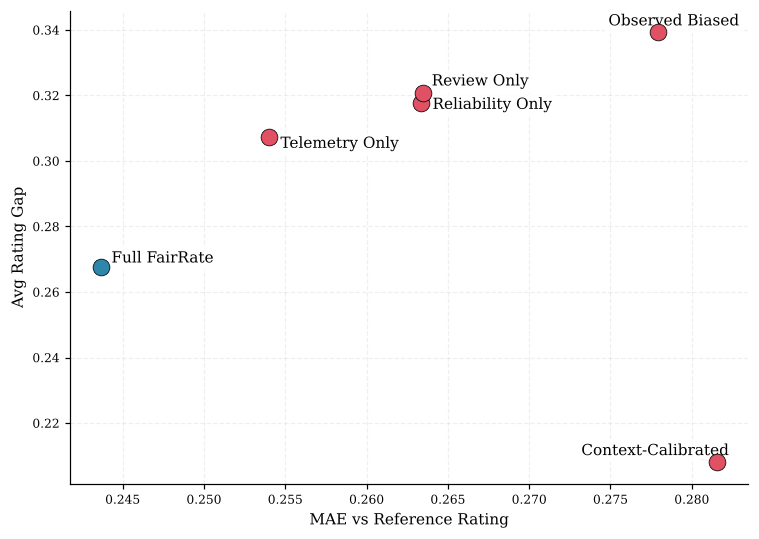

In [31]:
from adjustText import adjust_text
fig, ax = plt.subplots(figsize=(7, 5))
texts = []
for _, r in tradeoff.iterrows():
    ax.scatter(r["MAE"], r["Avg Rating Gap"], color=C1 if r["Method"] == "Full FairRate" else C2,
               s=120, edgecolor="black", linewidth=0.5, zorder=5)
    texts.append(ax.text(r["MAE"], r["Avg Rating Gap"], r["Method"], fontsize=10,
                         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85)))
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7))
ax.set_xlabel("MAE vs Reference Rating"); ax.set_ylabel("Avg Rating Gap")
plt.tight_layout(); savefig("15_fairness_accuracy_tradeoff"); plt.show()

## 18. Rating distributions for platform and environment reviews

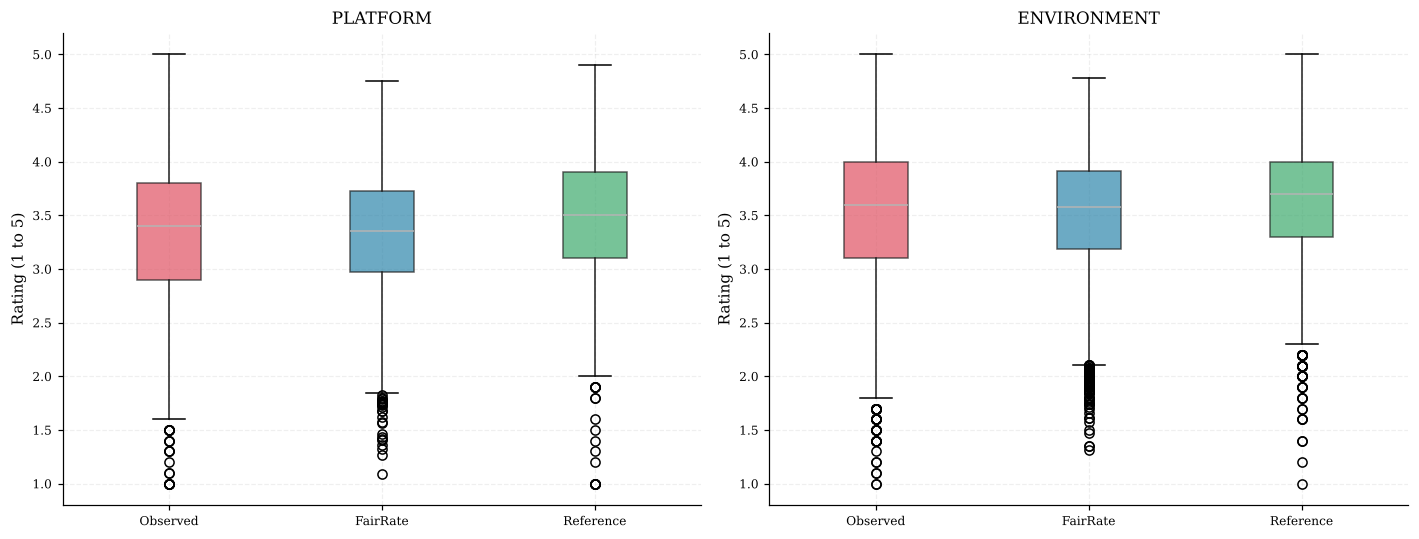

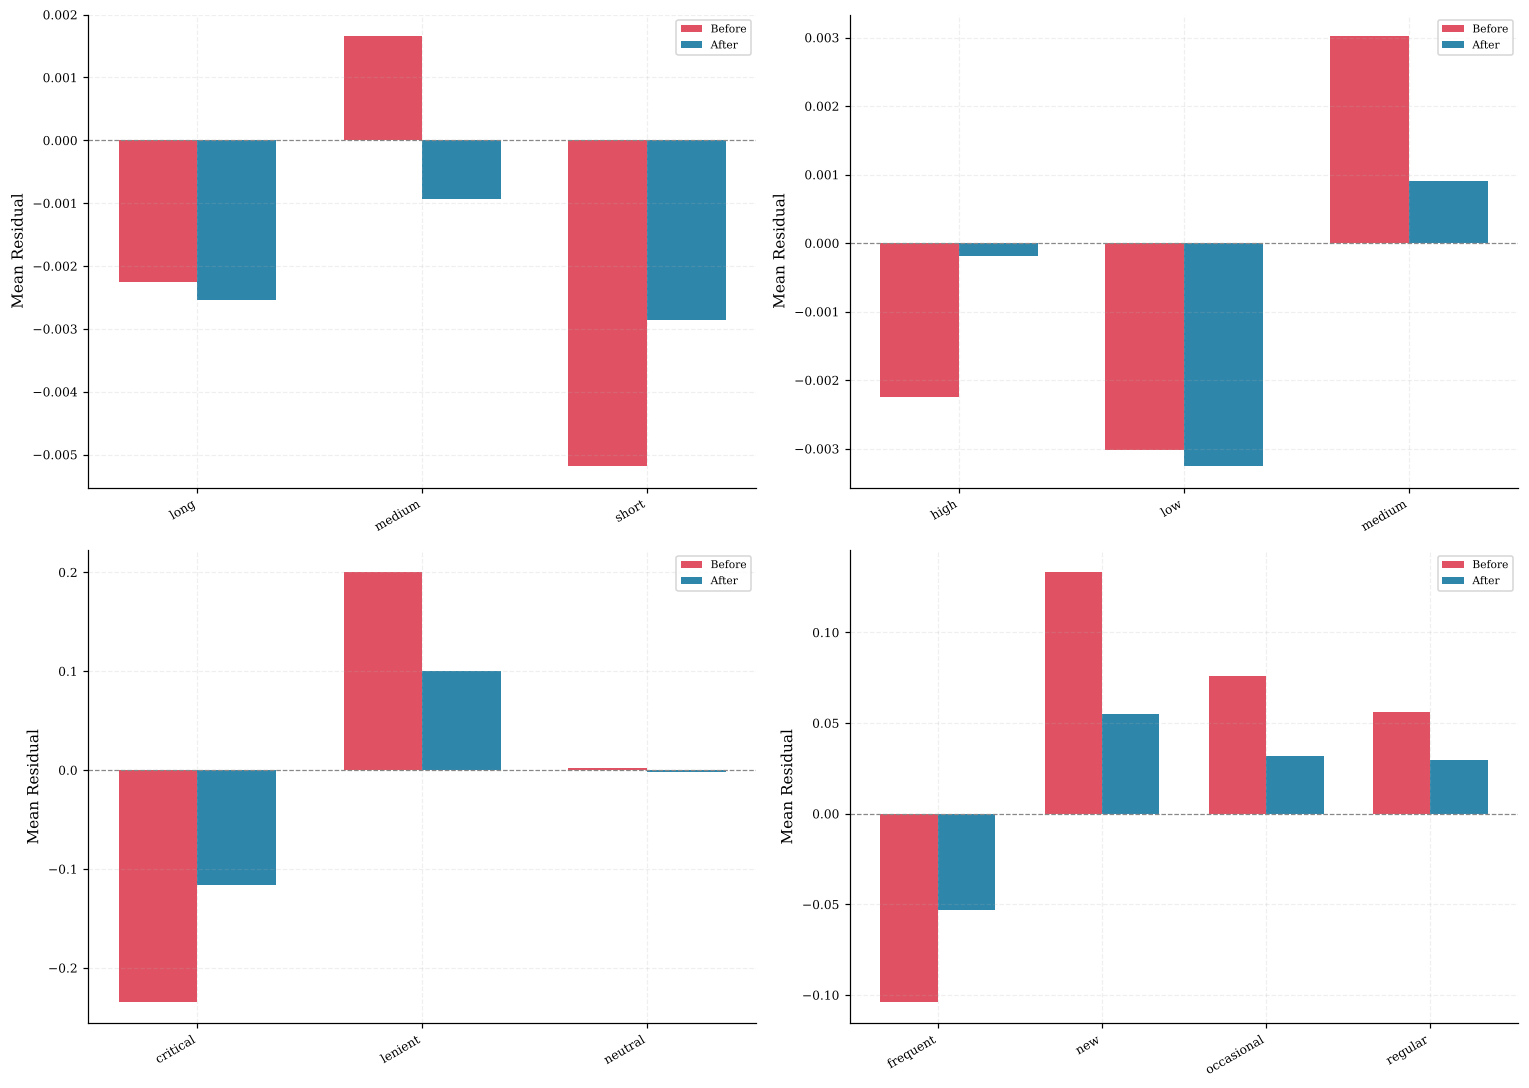

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cat in zip(axes, ["PLATFORM", "ENVIRONMENT"]):
    sub = df[df["review_cat"] == cat]
    data = pd.DataFrame({"Observed": sub["observed"], "FairRate": sub["fairrate"], "Reference": sub["clean_ref"]})
    bp = data.boxplot(ax=ax, return_type="dict", patch_artist=True)
    for patch, c in zip(bp["boxes"], [C2, C1, C3]):
        patch.set_facecolor(c); patch.set_alpha(0.7)
    ax.set_title(cat); ax.set_ylabel("Rating (1 to 5)")
plt.tight_layout(); savefig("13_boxplot_protection"); plt.show()

df["fair_res"] = df["fairrate"] - df["ctx_expected"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, g in zip(axes.flatten(), ["wait_bin", "cost_shock_bin", "rider_personality", "rider_tier"]):
    bef = df.groupby(g)["ctx_residual"].mean(); aft = df.groupby(g)["fair_res"].mean()
    x = np.arange(len(bef)); w = 0.35
    ax.bar(x - w/2, bef, w, label="Before", color=C2); ax.bar(x + w/2, aft, w, label="After", color=C1)
    ax.set_xticks(x); ax.set_xticklabels(bef.index, rotation=30, ha="right")
    ax.axhline(0, ls="--", color=C6, lw=.8); ax.set_ylabel("Mean Residual"); ax.legend(fontsize=7)
plt.tight_layout(); savefig("14_residual_by_group"); plt.show()

## 19. Save outputs

In [33]:
save_cols = ["driver_id", "rider_id", "pickup_time", "observed", "clean_ref", "rating_shift",
             "ctx_expected", "ctx_residual", "E_r", "I_r", "C_r", "H_r", "M_r", "reliability",
             "review_cat", "kw_label", "sentiment", "telemetry_q", "correction", "fairrate",
             "wait_bin", "weather_bin", "cost_shock_bin", "distance_bin",
             "rider_personality", "rider_age_group", "rider_tier", "rider_borough"]
df[save_cols].to_csv(OUT / "fairrate_trip_scores.csv", index=False)
rep_fair.groupby("driver_id").tail(1)[["driver_id", "new"]].to_csv(OUT / "driver_reputation.csv", index=False)
for name, tbl in [("split_info", split_info), ("context_models", ctx_df), ("cv_consecutive_blocks", cv_df),
                  ("cv_forward", fwd_df), ("residual_gap", res_gap), ("baselines", bl_df),
                  ("parity_gap", gap_df), ("category_protection", cat_sum), ("ablation", abl_df),
                  ("holdout_time_test", holdout_df), ("sensitivity", sens_df), ("metrics", metrics),
                  ("fairness_accuracy_tradeoff", tradeoff)]:
    tbl.to_csv(OUT / f"{name}.csv", index=False)
pd.DataFrame([{"alpha": ALPHA_OPT, "beta": BETA_OPT, "gamma": GAMMA_OPT, "tau": TAU, "max_corr": MAX_CORR,
               "lambda": LAMBDA, "delta": DELTA, "init": INIT}]).to_csv(OUT / "selected_parameters.csv", index=False)
print(sorted(p.name for p in OUT.glob("*.csv")))

['ablation.csv', 'baselines.csv', 'category_protection.csv', 'context_models.csv', 'cv_consecutive_blocks.csv', 'cv_forward.csv', 'driver_reputation.csv', 'fairness_accuracy_tradeoff.csv', 'fairrate_trip_scores.csv', 'holdout_time_test.csv', 'metrics.csv', 'parity_gap.csv', 'residual_gap.csv', 'selected_parameters.csv', 'sensitivity.csv', 'split_info.csv']


## 20. Summary tables

In [34]:
for title, tbl in [("Context models (Panel I, test set vs observed rating)", ctx_df),
                   ("FairRate and variants (Panel II, all trips vs reference)", bl_df),
                   ("Ablation (Panel III)", abl_df),
                   ("Rating gaps", gap_df),
                   ("Error by review category (Table 4)", cat_sum),
                   ("Held out time test", holdout_df),
                   ("Additional metrics", metrics)]:
    print("=" * 70); print(title); print("=" * 70)
    print(tbl.round(4).to_string(index=False)); print()

Context models (Panel I, test set vs observed rating)
       Model  Val MAE  Test MAE  Test RMSE  Test R2
    CatBoost   0.2931    0.2923     0.3693   0.6695
     XGBoost   0.2978    0.2956     0.3785   0.6530
    LightGBM   0.2958    0.2961     0.3777   0.6543
RandomForest   0.3208    0.3246     0.4100   0.5928
       Ridge   0.3726    0.3692     0.4636   0.4794

FairRate and variants (Panel II, all trips vs reference)
            Method    MAE   RMSE     R2
     Full FairRate 0.2437 0.3082 0.6674
    Telemetry Only 0.2540 0.3244 0.6314
  Reliability Only 0.2633 0.3367 0.6029
       Review Only 0.2635 0.3395 0.5962
   Observed Biased 0.2779 0.3602 0.5455
Context-Calibrated 0.2816 0.3534 0.5626

Ablation (Panel III)
      Variant    MAE   RMSE     R2
Full FairRate 0.2437 0.3082 0.6674
      -Review 0.2452 0.3108 0.6617
 -Reliability 0.2470 0.3149 0.6527
   -Telemetry 0.2517 0.3215 0.6380
 Context Only 0.2816 0.3534 0.5626
No Correction 0.2779 0.3602 0.5455

Rating gaps
            Grou